# Giai đoạn 1 (bản 4) – 4 bộ CICFlowMeter, chia theo đợt, NGƯỠNG NGUỒN

**Khác bản 3:** mỗi chuyên gia không còn dùng ngưỡng cố định 0,5 nữa. Nó tự chọn **ngưỡng nguồn**: ngưỡng cho Macro-F1 (trung bình F1 của lớp tấn công và lớp bình thường) cao nhất trên tập kiểm định của chính miền nguồn. Miền nguồn có nhãn nên việc này hợp lệ, không dùng nhãn miền đích. Kết quả ở ngưỡng 0,5 vẫn được ghi song song để so sánh.

Dữ liệu dùng lại cache `MyDrive/TADP_Q1/cache_cic/` (không tải lại). Kết quả lưu vào thư mục **mới** `MyDrive/TADP_Q1/results/v4_cic_nguong_nguon/`.

| Ô | Việc | Thời gian |
|---|---|---|
| 1 | Kiểm tra môi trường và phiên bản mã nguồn | 1 phút |
| 2 | Chạy 16 tổ hợp thực nghiệm | 1–2 giờ |
| 3 | Tổng hợp kết quả | 1 phút |

**Trước khi chạy:** *Runtime → Change runtime type → T4 GPU → Save*. Nếu bạn vừa mở notebook khác trong cùng phiên, chọn *Runtime → Restart session* để Colab nạp mã nguồn mới. Nếu Colab bị ngắt ở Ô 2, chạy lại Ô 2: tổ hợp đã xong sẽ được bỏ qua.

## Ô 1 – Kiểm tra môi trường và mã nguồn

In [1]:
import os, sys, subprocess
from google.colab import drive
drive.mount("/content/drive")
CODE_DIR = "/content/drive/MyDrive/TADP_Q1/code"
sys.path.insert(0, CODE_DIR)
for m in [k for k in sys.modules if k.startswith("tadp")]:
    del sys.modules[m]   # xóa bản mã nguồn cũ Colab còn nhớ

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ – hãy chọn Runtime → Change runtime type → T4 GPU")
try:
    import lightgbm, pyarrow
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "pyarrow"], check=True)
    import lightgbm, pyarrow

EXPECTED = {"__init__.py": 125, "cic_data.py": 8579, "config.py": 3263, "data.py": 9956, "experts.py": 5614,
            "metrics.py": 4002, "phase1.py": 9106, "preprocess.py": 3601, "shift.py": 3863, "summary.py": 6028}
ok = True
for f, size in EXPECTED.items():
    p = os.path.join(CODE_DIR, "tadp", f)
    real = os.path.getsize(p) if os.path.exists(p) else None
    if real != size:
        ok = False
        print(f"   SAI: {f} – mong đợi {size} byte, thực tế {real}")
print("Mã nguồn:", "ĐẦY ĐỦ, đúng phiên bản 4 (ngưỡng nguồn)" if ok else "CÓ LỖI – báo lại cho Claude")

Mounted at /content/drive
GPU: KHÔNG CÓ – hãy chọn Runtime → Change runtime type → T4 GPU
Mã nguồn: ĐẦY ĐỦ, đúng phiên bản 4 (ngưỡng nguồn)


## Ô 2 – Chạy thực nghiệm (16 tổ hợp)

Mỗi chuyên gia in ra 1 dòng, ví dụ:
`chuyên gia CIC-UNSW-NB15 : ngưỡng nguồn = 0.180 | Macro-F1 kiểm thử trong miền: ngưỡng nguồn = 0.88, ngưỡng 0,5 = 0.65 | AUROC = 0.996`

- **ngưỡng nguồn**: ngưỡng chuyên gia tự chọn;
- hai con số Macro-F1: cách mới và cách cũ, để bạn so sánh ngay;
- **AUROC** (diện tích dưới đường cong ROC): khả năng xếp hạng, không phụ thuộc ngưỡng.

In [2]:
import sys
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
for m in [k for k in sys.modules if k.startswith("tadp")]:
    del sys.modules[m]
from tadp.config import get_config
from tadp.phase1 import run_phase1
B = "/content/drive/MyDrive/TADP_Q1"
DOMAINS_CIC = {"CIC-IDS2017": ["2017"], "CSE-CIC-IDS2018": ["2018"], "CIC-ToN-IoT": ["ton"], "CIC-UNSW-NB15": ["unsw"]}
cfg = get_config(RAW_DIR=f"{B}/raw_cic", CACHE_DIR=f"{B}/cache_cic", RESULT_DIR=f"{B}/results/v4_cic_nguong_nguon",
                 DOMAINS=DOMAINS_CIC, SPLIT_MODE="episode")
run_phase1(cfg)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thiết bị tính toán: cpu
CIC-IDS2017: 999,712 dòng, 87 cột, tỷ lệ tấn công = 0.2411
CSE-CIC-IDS2018: 999,829 dòng, 87 cột, tỷ lệ tấn công = 0.0559
CIC-ToN-IoT: 1,000,028 dòng, 82 cột, tỷ lệ tấn công = 0.5302
CIC-UNSW-NB15: 1,000,399 dòng, 82 cột, tỷ lệ tấn công = 0.0251

Tỷ lệ tấn công ở từng phần dữ liệu:
     bo_du_lieu cach_chia  so_dot  ty_le_tan_cong_train  ty_le_tan_cong_val  ty_le_tan_cong_test  ty_le_tan_cong_adapt  ty_le_tan_cong_eval  so_loai_tan_cong_train  so_loai_tan_cong_val  so_loai_tan_cong_test  so_loai_tan_cong_eval
    CIC-IDS2017  theo_dot      20                0.2411              0.2411               0.2411                0.2411               0.2411                      15                    13                     15                     15
CSE-CIC-IDS2018  theo_dot      26                0.0559              0.0559               0.0559    

## Ô 3 – Tổng hợp kết quả

In ra các bảng A, B, B0.5, C, D và bản đồ nhiệt. Chạy xong thì báo Claude, Claude sẽ tự đọc các file trong `results/v4_cic_nguong_nguon/`.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BẢNG A – chuyển giao từng cặp nguồn → đích (trung bình)
                                    auroc  ty_le_dao_chieu  macro_f1_t05  macro_f1_thr_src  macro_f1_em  macro_f1_em_thr  macro_f1_bbse_thr  macro_f1_oracle_thr  macro_f1_constant  in_domain_macro_f1_t05  in_domain_macro_f1  in_domain_auroc
preproc           features model                                                                                                                                                                                                               
P1_log            all      mlp    0.6458           0.3333        0.5288            0.5276       0.5306           0.5294             0.5433               0.6485             0.4393                  0.9750              0.9750           0.9989
P0_paper          all      lgbm   0.5797           0.3333        0.4900            0.4727     

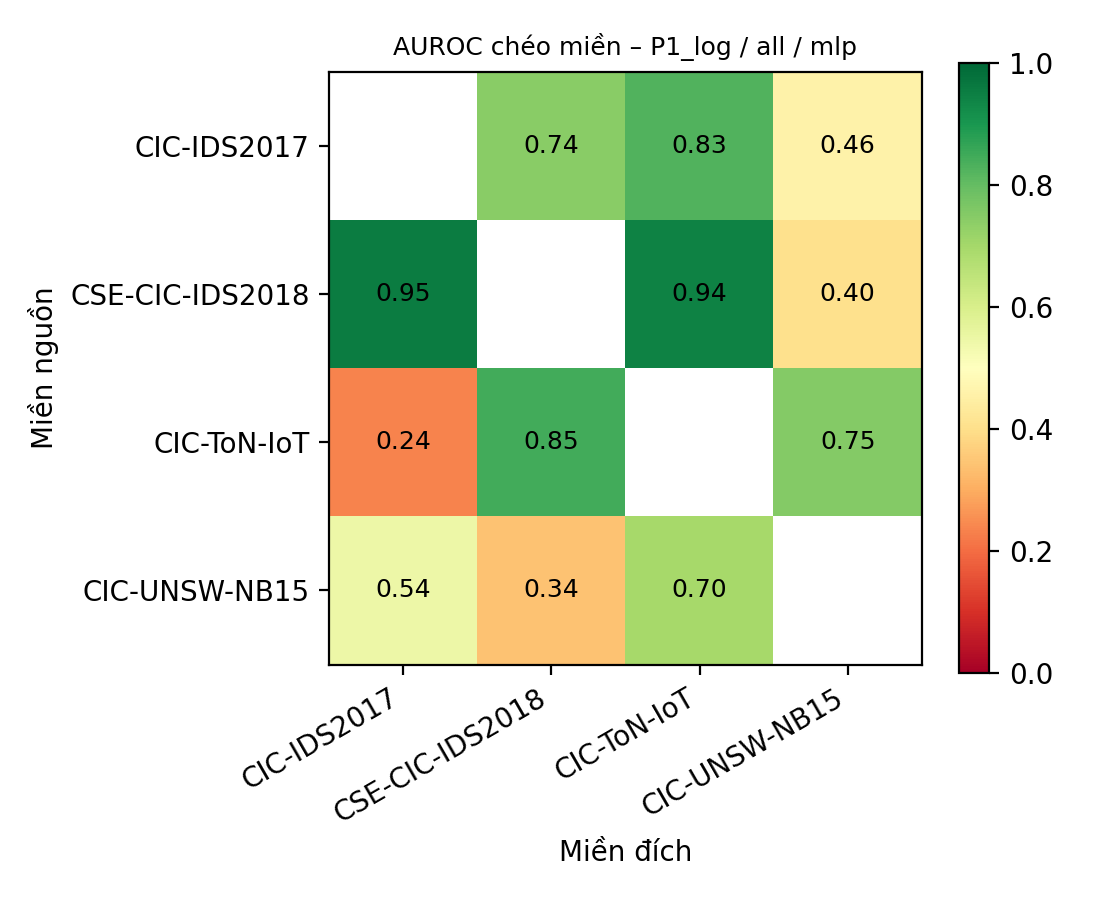

In [3]:
import sys
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
for m in [k for k in sys.modules if k.startswith("tadp")]:
    del sys.modules[m]
from tadp.config import get_config
from tadp.summary import summarize
from IPython.display import Image, display
B = "/content/drive/MyDrive/TADP_Q1"
DOMAINS_CIC = {"CIC-IDS2017": ["2017"], "CSE-CIC-IDS2018": ["2018"], "CIC-ToN-IoT": ["ton"], "CIC-UNSW-NB15": ["unsw"]}
cfg = get_config(RAW_DIR=f"{B}/raw_cic", CACHE_DIR=f"{B}/cache_cic", RESULT_DIR=f"{B}/results/v4_cic_nguong_nguon",
                 DOMAINS=DOMAINS_CIC, SPLIT_MODE="episode")
summarize(cfg)
display(Image(f"{cfg['RESULT_DIR']}/phase1_auroc_heatmap.png"))